## ELN risk group reclassification — Stage 3 of 3: Analysis

Reads ELN classification output written by `7_modify_eln_risk_groups.R` from
`data/{DATA_VERSION_IDENTIFIER}/eln/r_output/` and produces:
- Kaplan-Meier survival curves per label-replacement mode and variable set
- Sankey patient-flow diagrams showing how patients move between ELN risk groups
- VAF distribution plots for NPM1 and FLT3-ITD true-positive vs. false-negative patients

**Run `6_eln_risk_group_generation.ipynb` and then `7_modify_eln_risk_groups.R` before running this notebook.**

**Experimental modes:**
- **TARGETS** — ELN risk groups are stratified using the true mutation labels (ground truth).
- **TP** — Positive labels are replaced by model predictions; only true positives remain positive; false negatives are flipped to negative.

In [1]:
from pathlib import Path
from config import (
    USE_DUMMY_DATA,
    BM_RUN_PATH, PB_RUN_PATH, FUSION_RUN_PATH,
    CLINICAL_DATA_PATH_BM, CLINICAL_DATA_PATH_PB,
    SURVIVAL_DATA_PATH_BM, SURVIVAL_DATA_PATH_PB,
    VAF_DATA_PATH_BM,
    SELECTED_VARIABLES,
    DATA_VERSION_IDENTIFIER,
    FONTSIZE,
)

# ── CONFIG ────────────────────────────────────────────────────────────────────
MODEL_PREDICTIONS_PATH_BM     = BM_RUN_PATH
MODEL_PREDICTIONS_PATH_PB     = PB_RUN_PATH
MODEL_PREDICTIONS_PATH_FUSION = FUSION_RUN_PATH
CLINICAL_DATA_FILE = CLINICAL_DATA_PATH_BM
SURVIVAL_DATA_FILE = SURVIVAL_DATA_PATH_BM
VAF_DATA_FILE      = VAF_DATA_PATH_BM

# Must match the value used in 6_eln_risk_group_generation.ipynb.
ELN_BASE_DIR = Path(f"data/{DATA_VERSION_IDENTIFIER}/eln")
# ELN_BASE_DIR = Path(f"/home/HUSTIETOALLAS/ext11670944/mounts/research/husdatalake/disease/scripts/AML_mutation_prediction/aml-mutation-prediction/data/{DATA_VERSION_IDENTIFIER}/eln")

R_OUTPUT_DIR = ELN_BASE_DIR / "r_output"

MODES = ["TARGETS", "TP"]
VARIABLE_SETS = {
    "selected_variables": SELECTED_VARIABLES,
    "NPM1": ["NPM1"],
    "FLT3-ITD": ["FLT3_ITD"]
}

# (model display name) → (predictions path, model_type, clinical_path, survival_path, slide_type)
MODALITIES = {
    "BM":     (MODEL_PREDICTIONS_PATH_BM,     "bm",     CLINICAL_DATA_PATH_BM, SURVIVAL_DATA_PATH_BM, "bm"),
    "PB":     (MODEL_PREDICTIONS_PATH_PB,     "pb",     CLINICAL_DATA_PATH_PB, SURVIVAL_DATA_PATH_PB, "pb"),
    "FUSION": (MODEL_PREDICTIONS_PATH_FUSION, "fusion", CLINICAL_DATA_PATH_BM, SURVIVAL_DATA_PATH_BM, "bm"),
}
# ──────────────────────────────────────────────────────────────────────────────

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath

from core.utils import load_predictions, add_confusion_categories, save_and_show
from core.visualization.kaplan_meier import plot_kaplan_meier_curves
from core.visualization.box_plot import plot_covariate_distributions

In [46]:
def get_data(model_results_path, clinical_data_path, survival_data_path, selected_variables):
    predicted_labels = load_predictions(model_results_path, selected_variables)
    predicted_labels = add_confusion_categories(predicted_labels, selected_variables)

    clinical_data = pd.read_csv(clinical_data_path)
    clinical_data.album_id = clinical_data.album_id.astype(str)
    predicted_labels.album_id = predicted_labels.album_id.astype(str)
    clinical_data = clinical_data.rename(columns={"year": "database_id"})

    df_merged = pd.merge(clinical_data, predicted_labels, on=["album_id", "database_id"], how="inner")

    df_survival = pd.read_excel(survival_data_path)
    eln_analysis_patients = df_survival[df_survival.cyto == True].henkilotunnus.to_list()
    df_merged = df_merged[df_merged.henkilotunnus.isin(eln_analysis_patients)]
    return df_merged


def get_data_for_sankey(df_survival, experiment, variable_set, slide_type, r_output_dir, run_id, model_type="fusion"):
    filename = f"aml_mut_pred_{experiment}_{variable_set}_{model_type}_eln_{slide_type}_{run_id}.csv"
    df = pd.read_csv(Path(r_output_dir) / filename)
    df = pd.merge(df_survival, df, on=["album_id", "database_id", "henkilotunnus"], how="inner")
    df = df.dropna(subset="ELN1")
    df = pd.concat([df, pd.get_dummies(df["ELN1"], prefix="ELN1").astype(bool)], axis=1)
    return df


def get_common_eln_ids(df_survival, variable_set, slide_type, r_output_dir, run_id, model_type="fusion"):
    """Intersection of patients with a valid ELN1 in both TARGETS and TP modes.

    Some patients receive ELN1=NA in TP mode when a false-negative prediction strips their only
    classifying mutation (e.g. NPM1), leaving no favorable, adverse, or intermediate criteria.
    Restricting both KM curves to this intersection ensures a like-for-like comparison.
    See the 'Patient population note' cell for the R-fix option.
    """
    ids = []
    for experiment in ["TARGETS", "TP"]:
        filename = f"aml_mut_pred_{experiment}_{variable_set}_{model_type}_eln_{slide_type}_{run_id}.csv"
        df = pd.read_csv(Path(r_output_dir) / filename)
        df = pd.merge(df_survival, df, on=["album_id", "database_id", "henkilotunnus"], how="inner")
        df = df.dropna(subset="ELN1")
        ids.append(set(df.henkilotunnus))
    common = ids[0] & ids[1]
    only_targets = ids[0] - ids[1]
    only_tp = ids[1] - ids[0]
    if only_targets or only_tp:
        print(
            f"  [{variable_set}, {model_type}] {len(only_targets)} patient(s) classifiable in TARGETS only, "
            f"{len(only_tp)} in TP only — excluded from KM comparison. N included: {len(common)}."
        )
    return common


ELN_RISK_MAP = {"Favorable": 0, "Intermediate": 1, "Adverse": 2}


def concordance_index(event_times, predicted_scores, event_observed):
    t = np.asarray(event_times, dtype=float)
    s = np.asarray(predicted_scores, dtype=float)
    e = np.asarray(event_observed, dtype=bool)
    t_i, t_j = t[:, None], t[None, :]
    s_i, s_j = s[:, None], s[None, :]
    e_i = e[:, None]
    admissible = e_i & (t_i < t_j)
    concordant = np.sum(admissible & (s_i > s_j))
    discordant = np.sum(admissible & (s_i < s_j))
    tied_risk  = np.sum(admissible & (s_i == s_j))
    n_usable = concordant + discordant + tied_risk
    if n_usable == 0:
        return float("nan")
    return float(concordant + 0.5 * tied_risk) / n_usable


def execute_eln_kaplan_meier_experiments(
    experiment, df_survival, variable_set, slide_type, r_output_dir, run_id,
    model_type="fusion", modality_name="", restrict_ids=None,
    xlim=(0, 96), figsize=(3, 2), fontsize=7, title=None, figure_type="main",
):
    filename = f"aml_mut_pred_{experiment}_{variable_set}_{model_type}_eln_{slide_type}_{run_id}.csv"
    df = pd.read_csv(Path(r_output_dir) / filename)
    df = pd.merge(df_survival, df, on=["album_id", "database_id", "henkilotunnus"], how="inner")
    df = df.dropna(subset="ELN1")
    if restrict_ids is not None:
        df = df[df.henkilotunnus.isin(restrict_ids)]
    df = pd.concat([df, pd.get_dummies(df["ELN1"], prefix="ELN1").astype(bool)], axis=1)

    assert len(df[df.cyto == False]) == 0

    max_time = df["time_dg_to_death"].max()
    df["time_dg_to_death"] = df["time_dg_to_death"].fillna(max_time) / 30

    risk_cols = df.filter(like="ELN1_").columns.to_list()
    colors = {"ELN1_Favorable": "tab:blue", "ELN1_Intermediate": "tab:orange", "ELN1_Adverse": "tab:red"}
    plot_title = title or f"Overall Survival by Risk Group ({experiment}, {modality_name})"
    fig = plot_kaplan_meier_curves(
        df=df, time_col="time_dg_to_death", event_col="died", group_cols=risk_cols,
        colors=colors, title=plot_title,
        xlim=xlim, figsize=figsize, fontsize=fontsize, xlabel="Time (months)",
    )
    save_and_show(fig, title=plot_title, figure_type=figure_type)

    risk_scores = df["ELN1"].map(ELN_RISK_MAP)
    valid = ~risk_scores.isna()
    c_idx = concordance_index(df.loc[valid, "time_dg_to_death"], risk_scores[valid], df.loc[valid, "died"])
    print(f"C-index ({experiment}): {c_idx:.3f}\n")


def plot_modified_patients_km(
    df, modified_henkilotunnus, modality_name, variable_set, label_suffix,
    xlim=(0, 96), figsize=(3, 2), fontsize=7, title=None, figure_type="main",
):
    df_mod = df[df.henkilotunnus.isin(modified_henkilotunnus)].copy()
    max_time = df_mod["time_dg_to_death"].max()
    df_mod["time_dg_to_death"] = df_mod["time_dg_to_death"].fillna(max_time) / 30
    risk_cols = df_mod.filter(like="ELN1_").columns.tolist()
    colors = {"ELN1_Favorable": "tab:blue", "ELN1_Intermediate": "tab:orange", "ELN1_Adverse": "tab:red"}
    plot_title = title or f"Modified patients — {label_suffix} ({variable_set}, {modality_name})"
    fig = plot_kaplan_meier_curves(
        df=df_mod, time_col="time_dg_to_death", event_col="died", group_cols=risk_cols,
        colors=colors, title=plot_title,
        xlim=xlim, figsize=figsize, fontsize=fontsize, xlabel="Time (months)",
    )
    save_and_show(fig, title=plot_title, figure_type=figure_type)


def plot_vaf_for_changed_patients(
    df_model, df_vaf, sankey_changed, variable, vaf_col, title,
    fontsize=7, label_mapping={True: "True\npositive", False: "False\nnegative"},
    xlabel="", ylabel="VAF (%)", num_columns=1,
    fig_width=1.5, fig_height=2, point_size=2.5, figure_type="main",
):
    patients = sankey_changed.henkilotunnus.to_list()
    df = df_model[["henkilotunnus", f"{vaf_col}_predicted"]].merge(
        df_vaf[["henkilotunnus", vaf_col]], on="henkilotunnus"
    ).dropna()
    df["true_positive"] = df[f"{vaf_col}_predicted"] == "TP"
    df = df.drop(columns=[f"{vaf_col}_predicted"])
    df = df[df[vaf_col] <= 100]
    df = df[(df.true_positive == True) | (df.henkilotunnus.isin(patients))]
    fig = plot_covariate_distributions(
        df, {vaf_col: variable}, "true_positive",
        fontsize=fontsize, label_mapping=label_mapping,
        xlabel=xlabel, ylabel=ylabel, num_columns=num_columns,
        fig_width=fig_width, fig_height=fig_height, point_size=point_size,
        custom_palette = {True: "tab:red", False: "tab:blue"}
    )
    save_and_show(fig, title=title, figure_type=figure_type)


def plot_patient_flow_sankey(
    df1,
    df2,
    id_col="henkilotunnus",
    group_col="ELN1",
    categories=("Favorable", "Intermediate", "Adverse"),
    color_map={
        "Favorable": "tab:blue",
        "Intermediate": "tab:orange",
        "Adverse": "tab:red",
    },
    normalize=False,
    title="Patient Flow Between Risk Groups",
    df_labels=("Starting point", "End point"),
    plot_width=5,
    plot_height=3,
    fontsize=7,
    node_width=0.03,
    pad=0.06,
    save_path=None,
    figure_type="main",
):
    df = df1[[id_col, group_col]].merge(df2[[id_col, group_col]], on=id_col, suffixes=("_t1", "_t2"))

    modified_patients = df[df[f"{group_col}_t1"] != df[f"{group_col}_t2"]]
    print(f"Num modified patients: {len(modified_patients)}")

    total = len(df)
    t1_counts = {c: (df[f"{group_col}_t1"] == c).sum() for c in categories}
    t2_counts = {c: (df[f"{group_col}_t2"] == c).sum() for c in categories}
    flow_counts = {
        (s, t): ((df[f"{group_col}_t1"] == s) & (df[f"{group_col}_t2"] == t)).sum()
        for s in categories for t in categories
    }

    n = len(categories)
    available = 1.0 - (n - 1) * pad

    def _node_positions(counts):
        y_top, y_bot = {}, {}
        cursor = 1.0
        for c in categories:
            h = (counts[c] / total) * available
            y_top[c] = cursor
            y_bot[c] = cursor - h
            cursor = y_bot[c] - pad
        return y_top, y_bot

    t1_y_top, t1_y_bot = _node_positions(t1_counts)
    t2_y_top, t2_y_bot = _node_positions(t2_counts)

    src_y_top, src_y_bot = {}, {}
    for s in categories:
        cursor = t1_y_top[s]
        for t in categories:
            cnt = flow_counts[(s, t)]
            if cnt > 0:
                h = (cnt / total) * available
                src_y_top[(s, t)] = cursor
                src_y_bot[(s, t)] = cursor - h
                cursor -= h

    tgt_y_top, tgt_y_bot = {}, {}
    for t in categories:
        cursor = t2_y_top[t]
        for s in categories:
            cnt = flow_counts[(s, t)]
            if cnt > 0:
                h = (cnt / total) * available
                tgt_y_top[(s, t)] = cursor
                tgt_y_bot[(s, t)] = cursor - h
                cursor -= h

    fig, ax = plt.subplots(figsize=(plot_width, plot_height))
    x0 = node_width
    x1 = 1.0 - node_width

    y_data_range = 1.04
    min_dy = (fontsize / 72) / (plot_height / y_data_range) * 1.3
    flow_labels = []

    for s in categories:
        for t in categories:
            cnt = flow_counts[(s, t)]
            if cnt == 0:
                continue
            syb, syt = src_y_bot[(s, t)], src_y_top[(s, t)]
            tyb, tyt = tgt_y_bot[(s, t)], tgt_y_top[(s, t)]
            verts = [
                (x0, syb), (0.5, syb), (0.5, tyb), (x1, tyb),
                (x1, tyt), (0.5, tyt), (0.5, syt), (x0, syt), (x0, syb),
            ]
            codes = [
                MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
                MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY,
            ]
            ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color_map.get(s, "#aaaaaa"), edgecolor="none", alpha=0.4))
            if s != t:
                y_mid = 0.25 * (syb + syt + tyb + tyt)
                label = f"{cnt / total:.1%}" if normalize else str(int(cnt))
                flow_labels.append([y_mid, label])

    flow_labels.sort(key=lambda x: -x[0])
    for i in range(1, len(flow_labels)):
        if flow_labels[i - 1][0] - flow_labels[i][0] < min_dy:
            flow_labels[i][0] = flow_labels[i - 1][0] - min_dy

    for y_adj, label in flow_labels:
        ax.text(0.5, y_adj, label, ha="center", va="center", fontsize=fontsize - 1, color="black")

    for c in categories:
        color = color_map.get(c, "#aaaaaa")
        ax.fill_betweenx([t1_y_bot[c], t1_y_top[c]], 0, node_width, color=color)
        ax.fill_betweenx([t2_y_bot[c], t2_y_top[c]], 1.0 - node_width, 1.0, color=color)
        ax.text(-0.01, (t1_y_top[c] + t1_y_bot[c]) / 2, f"{c}\nN = {t1_counts[c]}", ha="right", va="center", fontsize=fontsize - 1)
        ax.text(1.01, (t2_y_top[c] + t2_y_bot[c]) / 2, f"{c}\nN = {t2_counts[c]}", ha="left", va="center", fontsize=fontsize - 1)

    ax.text(node_width / 2, 1.04, df_labels[0], ha="center", va="bottom", fontsize=fontsize - 1, fontweight="bold")
    ax.text(1.0 - node_width / 2, 1.04, df_labels[1], ha="center", va="bottom", fontsize=fontsize - 1, fontweight="bold")
    ax.set_xlim(-0.35, 1.35)
    ax.set_ylim(-0.02, 1.15)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fontsize)
    save_and_show(fig, title=title, figure_type=figure_type)
    return modified_patients

In [4]:
df_models = {}
df_survivals = {}
for modality_name, (model_path, _, clinical_path, survival_path, _slide) in MODALITIES.items():
    df_models[modality_name] = get_data(model_path, clinical_path, survival_path, SELECTED_VARIABLES)
    df_survivals[modality_name] = pd.read_excel(survival_path)

df_vaf = pd.read_excel(VAF_DATA_FILE)

---
**Patient population note — TARGETS vs TP KM comparison**

The R ELN classifier (`7_modify_eln_risk_groups.R`) assigns `ELN1 = NA` when a patient has no
favorable, adverse, *or* intermediate criteria. The intermediate rule requires at least one positive
finding (`FLT3_ITD`, `t_9_11`, MLLT3 fusion, non-empty karyotype, or non-empty mutations string).
Under TP mode a false-negative prediction for a patient's only classifying mutation — most commonly
NPM1 (favorable when FLT3-ITD is absent) — flips that label to negative, leaving the patient with
no classifiable genetic feature and therefore `ELN1 = NA`.

**Current fallback — intersection method:** `get_common_eln_ids()` returns the patients who have a
valid ELN1 in **both** TARGETS and TP. Both KM curves are restricted to this intersection so they
describe exactly the same cohort and the visual comparison is meaningful. The Sankey diagram already
uses the same intersection via its inner join. A diagnostic message is printed whenever patients are
excluded.

**R-fix option** — apply this if the intersection excludes a clinically significant number of
patients. Change **line 84** of `7_modify_eln_risk_groups.R` so that Intermediate is the default
fallback for any patient who is neither Favorable nor Adverse (the ELN 2022 intent):

```r
# Current — requires a positive intermediate criterion:
ELN1_int = ifelse((ELN1_fav == 0 | ELN1_adv == 0) &
                  (FLT3_ITD == "POS" | t_9_11=="POS" |
                   str_detect(fuus, "(?i)(MLLT3)") |
                   !karyotype=="" | !mutations==""), 1, 0)

# Proposed — Intermediate = not Favorable and not Adverse:
ELN1_int = ifelse(ELN1_fav == 0 & ELN1_adv == 0, 1, 0)
```

Trade-off: patients with entirely empty cytogenetics and mutation fields are labelled Intermediate,
which may not reflect clinical practice when data is genuinely missing rather than negative.
After applying the fix, rerun: **notebook 6 → `7_modify_eln_risk_groups.R` → this notebook**.

---

### **ELN modified using all variables**

#### BM

  [selected_variables, bm] 2 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 265.


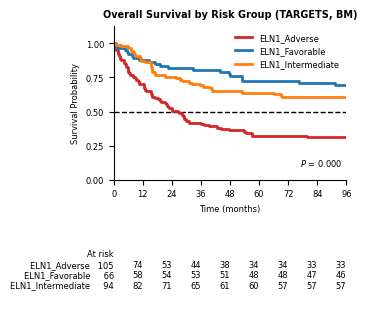

C-index (TARGETS): 0.636



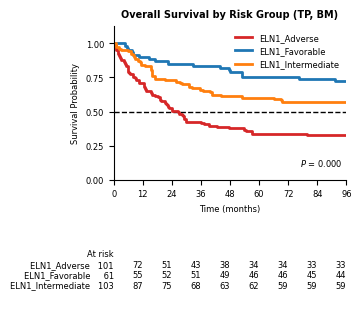

C-index (TP): 0.635



In [5]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
_common_ids = get_common_eln_ids(
    df_survivals["BM"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["BM"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["BM"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)

Num modified patients: 17


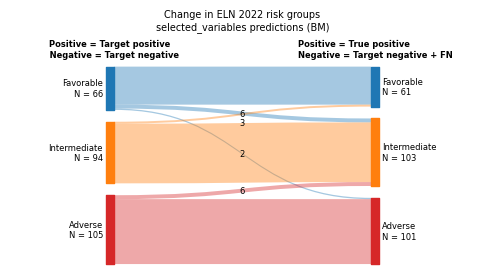

In [6]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
df1_all_bm = get_data_for_sankey(df_survivals["BM"], "TARGETS", "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_all_bm = get_data_for_sankey(df_survivals["BM"], "TP",      "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_all_bm = plot_patient_flow_sankey(
    df1_all_bm, df2_all_bm,
    title="Change in ELN 2022 risk groups\nselected_variables predictions (BM)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

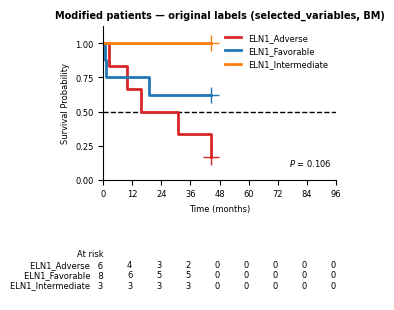

In [7]:
plot_modified_patients_km(df1_all_bm, modified_all_bm.henkilotunnus, "BM", "selected_variables", "original labels")

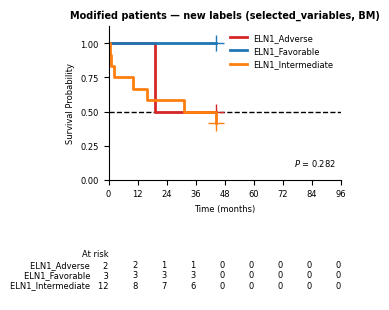

In [8]:
plot_modified_patients_km(df2_all_bm, modified_all_bm.henkilotunnus, "BM", "selected_variables", "new labels")

#### PB

  [selected_variables, pb] 2 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 265.


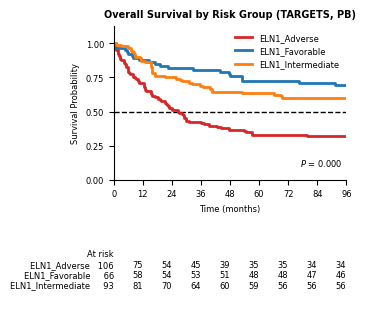

C-index (TARGETS): 0.634



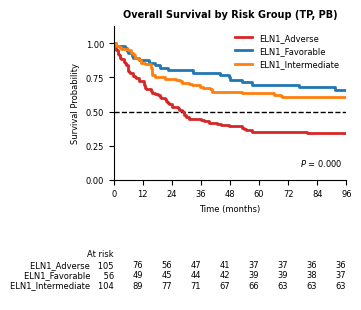

C-index (TP): 0.615



In [9]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
_common_ids = get_common_eln_ids(
    df_survivals["PB"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["PB"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["PB"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)

Num modified patients: 18


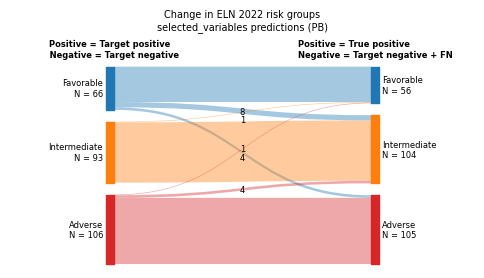

In [10]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
df1_all_pb = get_data_for_sankey(df_survivals["PB"], "TARGETS", "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_all_pb = get_data_for_sankey(df_survivals["PB"], "TP",      "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_all_pb = plot_patient_flow_sankey(
    df1_all_pb, df2_all_pb,
    title="Change in ELN 2022 risk groups\nselected_variables predictions (PB)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

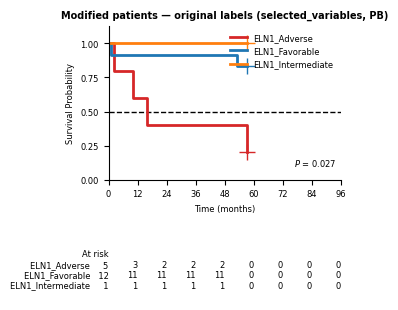

In [11]:
plot_modified_patients_km(df1_all_pb, modified_all_pb.henkilotunnus, "PB", "selected_variables", "original labels")

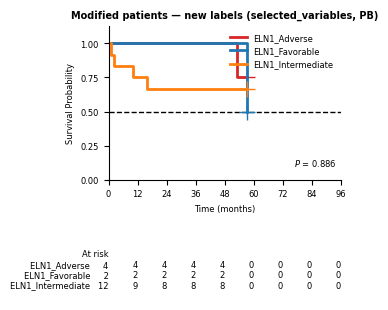

In [12]:
plot_modified_patients_km(df2_all_pb, modified_all_pb.henkilotunnus, "PB", "selected_variables", "new labels")

#### FUSION

  [selected_variables, fusion] 6 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 261.


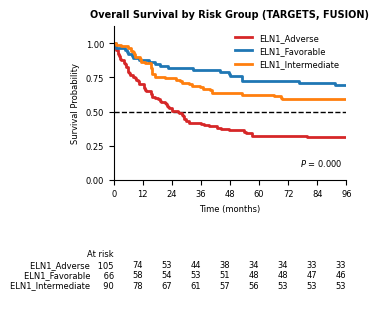

C-index (TARGETS): 0.635



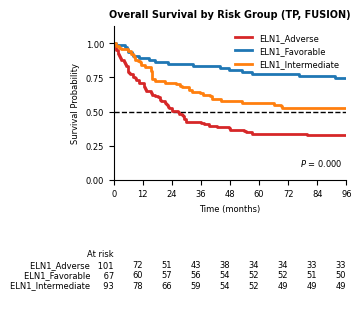

C-index (TP): 0.636



In [13]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
_common_ids = get_common_eln_ids(
    df_survivals["FUSION"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["FUSION"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["FUSION"], "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)

Num modified patients: 22


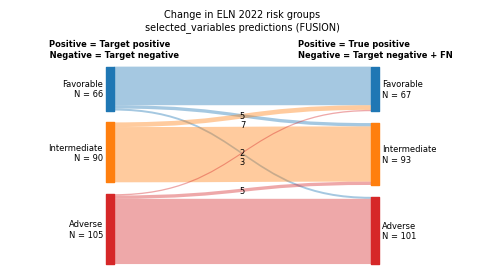

In [14]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
df1_all_fusion = get_data_for_sankey(df_survivals["FUSION"], "TARGETS", "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_all_fusion = get_data_for_sankey(df_survivals["FUSION"], "TP",      "selected_variables", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_all_fusion = plot_patient_flow_sankey(
    df1_all_fusion, df2_all_fusion,
    title="Change in ELN 2022 risk groups\nselected_variables predictions (FUSION)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

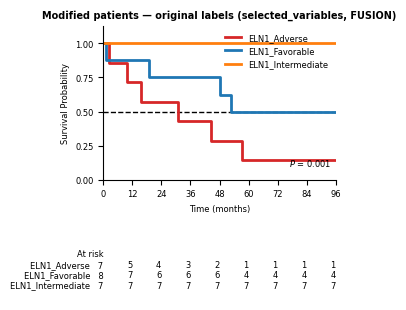

In [15]:
plot_modified_patients_km(df1_all_fusion, modified_all_fusion.henkilotunnus, "FUSION", "selected_variables", "original labels")

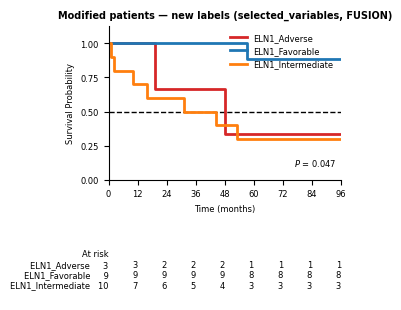

In [16]:
plot_modified_patients_km(df2_all_fusion, modified_all_fusion.henkilotunnus, "FUSION", "selected_variables", "new labels")

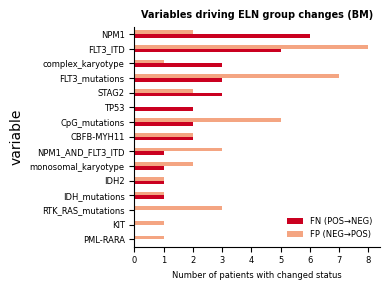

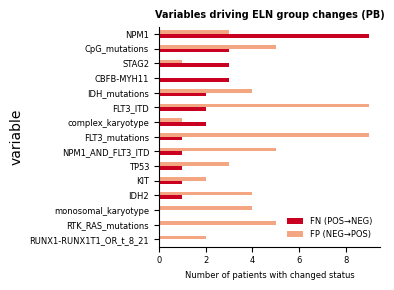

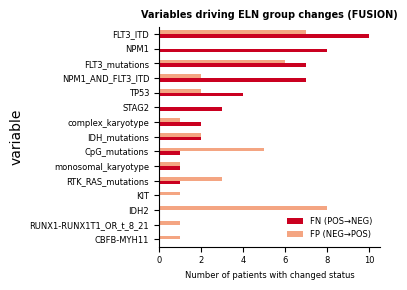

In [17]:
# Which variables drove ELN group changes? (selected_variables set, TARGETS → TP mode)
modified_selected_variables = {"BM": modified_all_bm, "PB": modified_all_pb, "FUSION": modified_all_fusion}

for modality_name in MODALITIES:
    changed_patients = modified_selected_variables[modality_name]
    df_model = df_models[modality_name]

    changed = df_model[df_model.henkilotunnus.isin(changed_patients.henkilotunnus)]

    rows = []
    for v in SELECTED_VARIABLES:
        col = f"{v}_predicted"
        if col not in changed.columns:
            continue
        fn_count = (changed[col] == "FN").sum()
        fp_count = (changed[col] == "FP").sum()
        if fn_count > 0 or fp_count > 0:
            rows.append({
                "variable": v,
                "FN (POS→NEG)": fn_count,
                "FP (NEG→POS)": fp_count,
            })

    if not rows:
        print(f"{modality_name}: no changed patients found in model data")
        continue

    df_counts = pd.DataFrame(rows).set_index("variable")
    df_counts = df_counts.sort_values("FN (POS→NEG)", ascending=True)

    fig, ax = plt.subplots(figsize=(4, max(2, len(df_counts) * 0.2)))
    df_counts.plot.barh(ax=ax, color=["#ca0020", "#f4a582"])
    ax.set_xlabel("Number of patients with changed status", fontsize=FONTSIZE - 1)
    ax.set_title(f"Variables driving ELN group changes ({modality_name})", fontsize=FONTSIZE, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=FONTSIZE - 1)
    ax.legend(frameon=False, fontsize=FONTSIZE - 1)
    plt.tight_layout()
    save_and_show(fig, title=f"ELN variable drivers {modality_name}", figure_type="main")

### **ELN modified using *NPM1***

#### BM

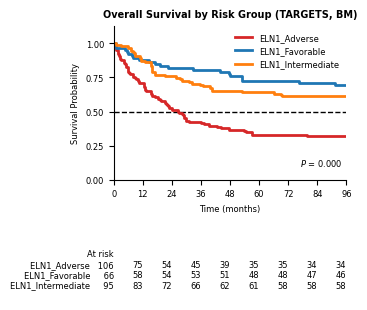

C-index (TARGETS): 0.635



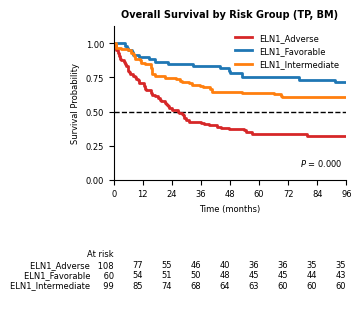

C-index (TP): 0.639



In [18]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
_common_ids = get_common_eln_ids(
    df_survivals["BM"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["BM"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["BM"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)

Num modified patients: 6


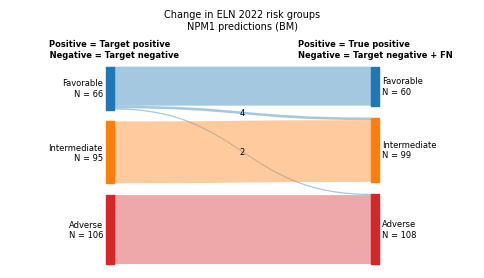

In [19]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
df1_npm1_bm = get_data_for_sankey(df_survivals["BM"], "TARGETS", "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_npm1_bm = get_data_for_sankey(df_survivals["BM"], "TP",      "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_npm1_bm = plot_patient_flow_sankey(
    df1_npm1_bm, df2_npm1_bm,
    title="Change in ELN 2022 risk groups\nNPM1 predictions (BM)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

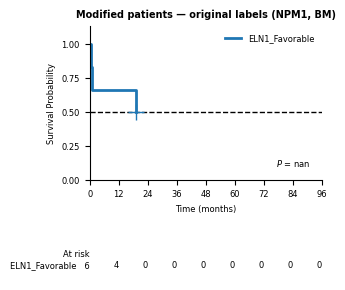

In [20]:
plot_modified_patients_km(df1_npm1_bm, modified_npm1_bm.henkilotunnus, "BM", "NPM1", "original labels")

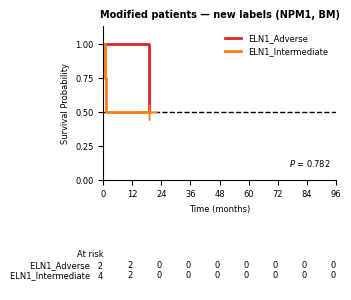

In [21]:
plot_modified_patients_km(df2_npm1_bm, modified_npm1_bm.henkilotunnus, "BM", "NPM1", "new labels")

#### PB

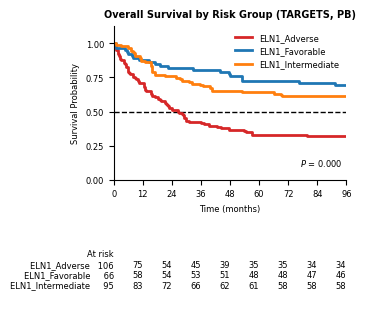

C-index (TARGETS): 0.635



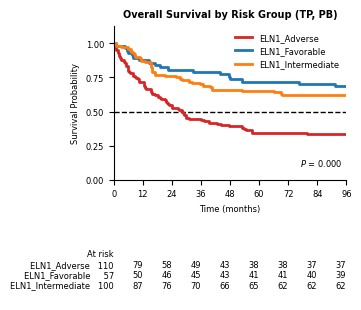

C-index (TP): 0.625



In [22]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
_common_ids = get_common_eln_ids(
    df_survivals["PB"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["PB"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["PB"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)

Num modified patients: 9


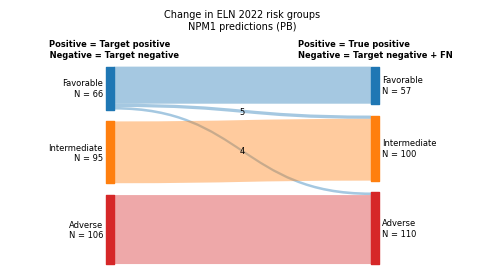

In [23]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
df1_npm1_pb = get_data_for_sankey(df_survivals["PB"], "TARGETS", "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_npm1_pb = get_data_for_sankey(df_survivals["PB"], "TP",      "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_npm1_pb = plot_patient_flow_sankey(
    df1_npm1_pb, df2_npm1_pb,
    title="Change in ELN 2022 risk groups\nNPM1 predictions (PB)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

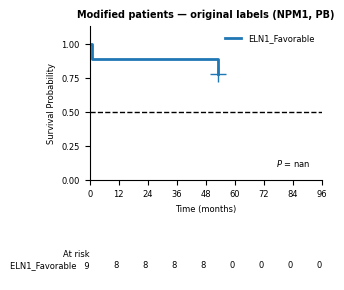

In [24]:
plot_modified_patients_km(df1_npm1_pb, modified_npm1_pb.henkilotunnus, "PB", "NPM1", "original labels")

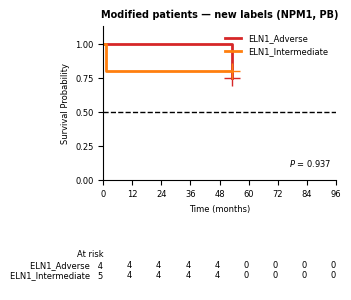

In [25]:
plot_modified_patients_km(df2_npm1_pb, modified_npm1_pb.henkilotunnus, "PB", "NPM1", "new labels")

#### FUSION

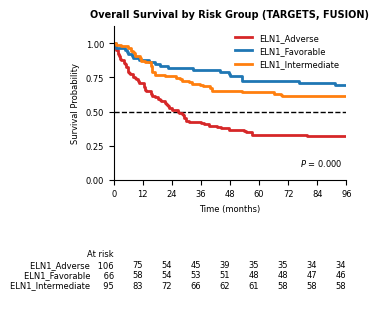

C-index (TARGETS): 0.635



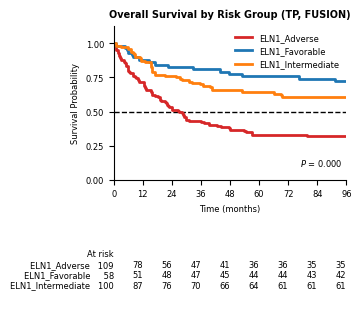

C-index (TP): 0.637



In [26]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
_common_ids = get_common_eln_ids(
    df_survivals["FUSION"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["FUSION"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["FUSION"], "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)

Num modified patients: 8


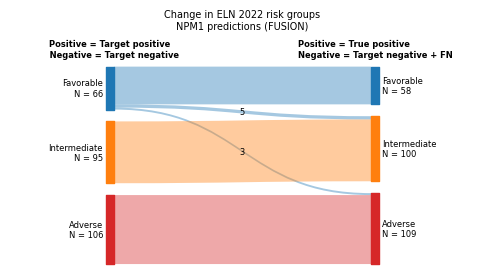

In [27]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
df1_npm1_fusion = get_data_for_sankey(df_survivals["FUSION"], "TARGETS", "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_npm1_fusion = get_data_for_sankey(df_survivals["FUSION"], "TP",      "NPM1", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_npm1_fusion = plot_patient_flow_sankey(
    df1_npm1_fusion, df2_npm1_fusion,
    title="Change in ELN 2022 risk groups\nNPM1 predictions (FUSION)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

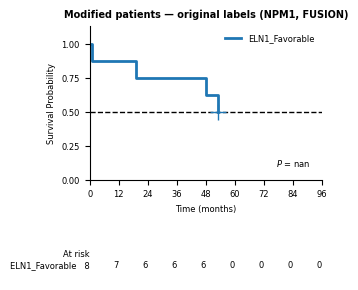

In [28]:
plot_modified_patients_km(df1_npm1_fusion, modified_npm1_fusion.henkilotunnus, "FUSION", "NPM1", "original labels")

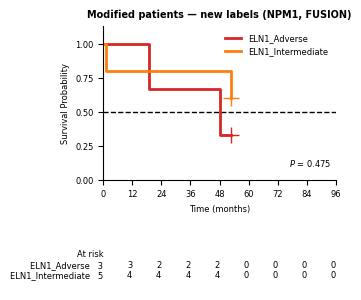

In [29]:
plot_modified_patients_km(df2_npm1_fusion, modified_npm1_fusion.henkilotunnus, "FUSION", "NPM1", "new labels")

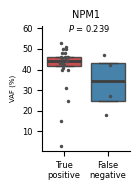

In [48]:
plot_vaf_for_changed_patients(
    df_models["FUSION"], df_vaf, modified_npm1_fusion,
    variable="NPM1", vaf_col="NPM1", title="NPM1 VAF TP vs FN",
    figure_type="main_npm1_vaf_tp_vs_fn",
)

### **ELN modified using *FLT3-ITD***

#### BM

  [FLT3-ITD, bm] 1 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 266.


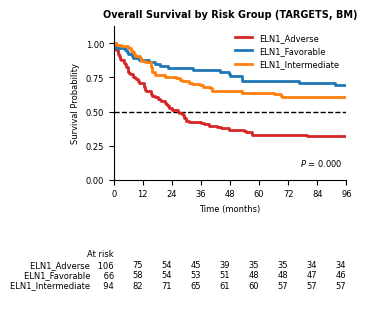

C-index (TARGETS): 0.635



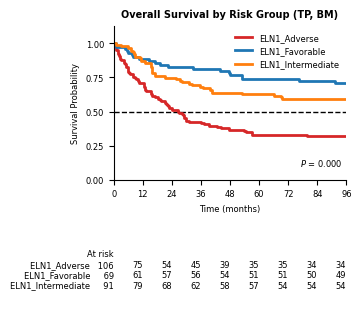

C-index (TP): 0.638



In [31]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
_common_ids = get_common_eln_ids(
    df_survivals["BM"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["BM"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["BM"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="BM", restrict_ids=_common_ids,
)

Num modified patients: 3


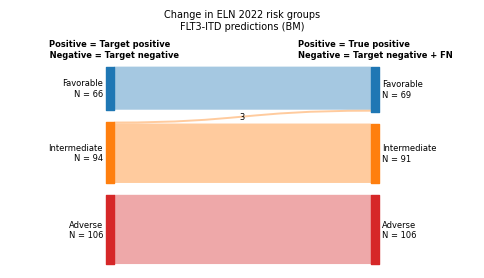

In [32]:
_, model_type, _, _, slide_type = MODALITIES["BM"]
df1_flt3_bm = get_data_for_sankey(df_survivals["BM"], "TARGETS", "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_flt3_bm = get_data_for_sankey(df_survivals["BM"], "TP",      "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_flt3_bm = plot_patient_flow_sankey(
    df1_flt3_bm, df2_flt3_bm,
    title="Change in ELN 2022 risk groups\nFLT3-ITD predictions (BM)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

In [33]:
#plot_modified_patients_km(df1_flt3_bm, modified_flt3_bm.henkilotunnus, "BM", "FLT3-ITD", "original labels")

In [34]:
#plot_modified_patients_km(df2_flt3_bm, modified_flt3_bm.henkilotunnus, "BM", "FLT3-ITD", "new labels")

#### PB

  [FLT3-ITD, pb] 1 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 266.


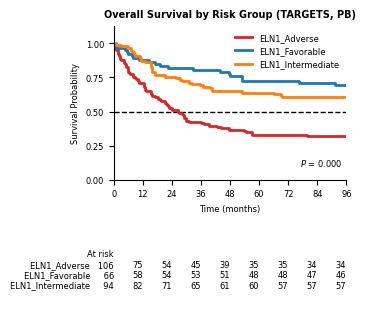

C-index (TARGETS): 0.635



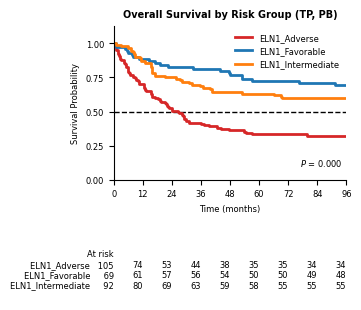

C-index (TP): 0.636



In [35]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
_common_ids = get_common_eln_ids(
    df_survivals["PB"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["PB"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["PB"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="PB", restrict_ids=_common_ids,
)

Num modified patients: 3


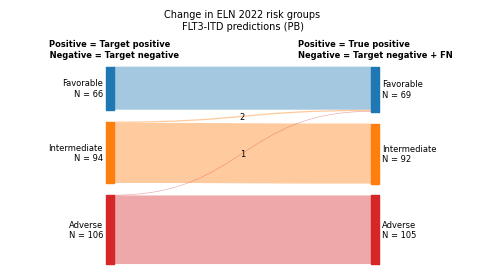

In [36]:
_, model_type, _, _, slide_type = MODALITIES["PB"]
df1_flt3_pb = get_data_for_sankey(df_survivals["PB"], "TARGETS", "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_flt3_pb = get_data_for_sankey(df_survivals["PB"], "TP",      "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_flt3_pb = plot_patient_flow_sankey(
    df1_flt3_pb, df2_flt3_pb,
    title="Change in ELN 2022 risk groups\nFLT3-ITD predictions (PB)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

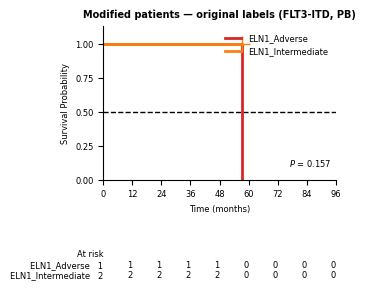

In [37]:
plot_modified_patients_km(df1_flt3_pb, modified_flt3_pb.henkilotunnus, "PB", "FLT3-ITD", "original labels")

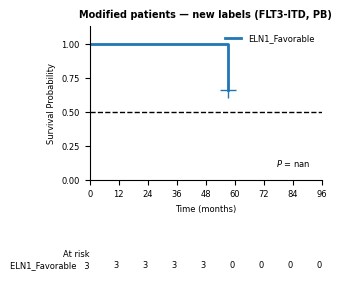

In [38]:
plot_modified_patients_km(df2_flt3_pb, modified_flt3_pb.henkilotunnus, "PB", "FLT3-ITD", "new labels")

#### FUSION

  [FLT3-ITD, fusion] 3 patient(s) classifiable in TARGETS only, 0 in TP only — excluded from KM comparison. N included: 264.


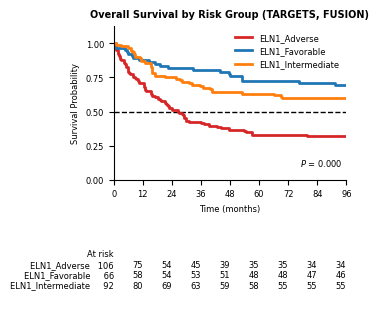

C-index (TARGETS): 0.634



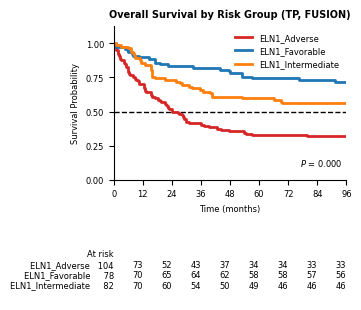

C-index (TP): 0.641



In [39]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
_common_ids = get_common_eln_ids(
    df_survivals["FUSION"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type,
)
execute_eln_kaplan_meier_experiments(
    "TARGETS", df_survivals["FUSION"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)
execute_eln_kaplan_meier_experiments(
    "TP", df_survivals["FUSION"], "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER,
    model_type=model_type, modality_name="FUSION", restrict_ids=_common_ids,
)

Num modified patients: 12


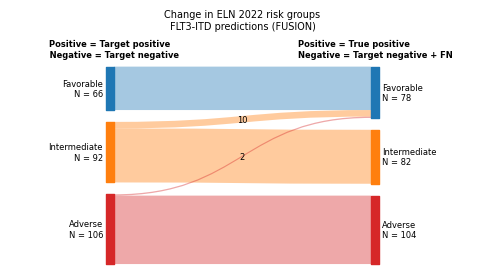

In [40]:
_, model_type, _, _, slide_type = MODALITIES["FUSION"]
df1_flt3_fusion = get_data_for_sankey(df_survivals["FUSION"], "TARGETS", "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
df2_flt3_fusion = get_data_for_sankey(df_survivals["FUSION"], "TP",      "FLT3-ITD", slide_type, R_OUTPUT_DIR, DATA_VERSION_IDENTIFIER, model_type=model_type)
modified_flt3_fusion = plot_patient_flow_sankey(
    df1_flt3_fusion, df2_flt3_fusion,
    title="Change in ELN 2022 risk groups\nFLT3-ITD predictions (FUSION)",
    df_labels=(
        "Positive = Target positive\n   Negative = Target negative",
        "Positive = True positive               \nNegative = Target negative + FN",
    ),
    plot_width=6, plot_height=3, fontsize=7,
)

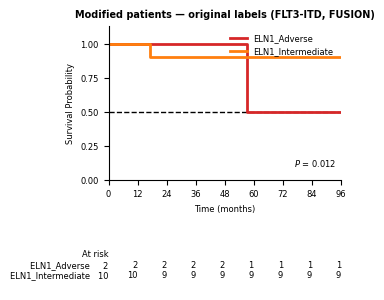

In [41]:
plot_modified_patients_km(df1_flt3_fusion, modified_flt3_fusion.henkilotunnus, "FUSION", "FLT3-ITD", "original labels")

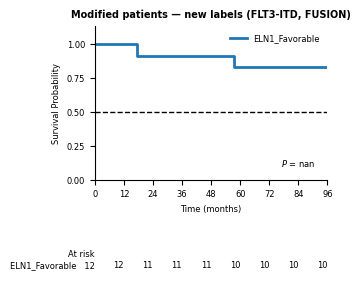

In [42]:
plot_modified_patients_km(df2_flt3_fusion, modified_flt3_fusion.henkilotunnus, "FUSION", "FLT3-ITD", "new labels")

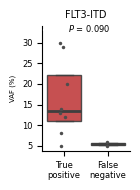

In [47]:
plot_vaf_for_changed_patients(
    df_models["FUSION"], df_vaf, modified_flt3_fusion,
    variable="FLT3-ITD", vaf_col="FLT3_ITD", title="FLT3-ITD VAF TP vs FN",
    figure_type="main",
)